# Day 036 | Linear Regression from Scratch

## 100 Days of ML for Geotechnical Engineering
**Phase:** Classical Machine Learning

**Author:** Ripon Chandra Malo  

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Linear model | `y = w*x + b` | Predict Vs from SPT N-value |
| Cost function (MSE) | Measures how wrong the model is | Error between predicted and measured Vs |
| Gradient descent | Iteratively adjust w, b to minimize cost | "Learning" the N-vs-Vs relationship |
| Learning rate | Step size for each update | Too big → overshoot, too small → slow |
| Normal equation | Closed-form solution (no iteration) | Direct formula for best-fit line |
| Convergence | Cost stops decreasing | Model has learned the pattern |

---

## Our Geotechnical Problem

**Predict shear wave velocity (Vs) from SPT N-value.**

The empirical correlation `Vs = 97 * N^0.314` is well-known in geotechnical practice. But imagine we only have field data — pairs of (N, Vs) — and we want to **learn** this relationship from scratch using linear regression.

We will:
1. Generate synthetic data following this correlation (with noise)
2. Build a linear regression model using only NumPy
3. Derive and implement gradient descent step by step
4. Visualize how the model learns
5. Compare with the closed-form normal equation

This is the **foundation of all machine learning** — understand this, and everything else builds on top.

---

## Part 1: Generate Synthetic Geotechnical Data

We simulate 50 field measurements of SPT N-value and corresponding shear wave velocity (Vs). The true relationship is nonlinear (`Vs = 97 * N^0.314`), but over a limited range, a linear model can approximate it reasonably well.

We add Gaussian noise to simulate real-world measurement variability.

In [1]:
# ─────────────────────────────────────────────────────
# IMPORTS
# ─────────────────────────────────────────────────────

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

print("Libraries loaded.")
print(f"NumPy version: {np.__version__}")

Libraries loaded.
NumPy version: 2.1.3


In [2]:
# ─────────────────────────────────────────────────────
# GENERATE SYNTHETIC DATA: SPT N-value → Vs
# ─────────────────────────────────────────────────────
# True relationship: Vs = 97 * N^0.314 + noise
# Reference: Imai & Tonouchi (1982)

n_samples = 50

# SPT N-values between 5 and 60
N_values = np.random.uniform(5, 60, n_samples)
N_values = np.sort(N_values)  # sort for cleaner plotting

# True Vs with Gaussian noise (std = 15 m/s)
noise = np.random.normal(0, 15, n_samples)
Vs_true = 97 * N_values**0.314 + noise

print(f"Generated {n_samples} synthetic data points")
print(f"N-value range: {N_values.min():.1f} to {N_values.max():.1f}")
print(f"Vs range:      {Vs_true.min():.1f} to {Vs_true.max():.1f} m/s")
print()
print("Sample data (first 10 points):")
print(f"  {'N-value':>8}  {'Vs (m/s)':>10}")
print("  " + "─" * 20)
for i in range(10):
    print(f"  {N_values[i]:8.1f}  {Vs_true[i]:10.1f}")

Generated 50 synthetic data points
N-value range: 6.1 to 58.3
Vs range:      168.3 to 359.3 m/s

Sample data (first 10 points):
   N-value    Vs (m/s)
  ────────────────────
       6.1       182.5
       6.9       180.4
       7.6       181.3
       8.2       183.3
       8.6       168.3
      10.4       191.4
      11.7       203.1
      12.7       231.2
      13.6       225.2
      13.6       193.6


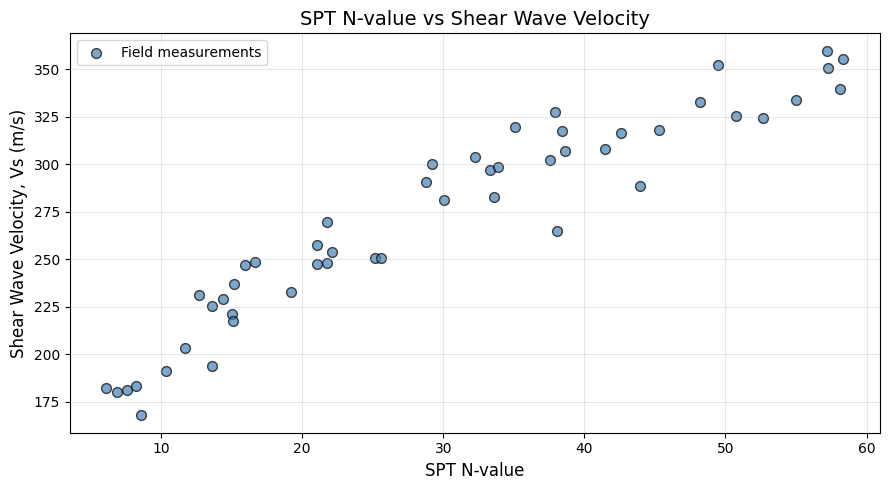

The data shows a positive trend — higher N → higher Vs.
Our goal: find the best-fit line y = w*x + b.


In [3]:
# ─────────────────────────────────────────────────────
# VISUALIZE THE RAW DATA
# ─────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(N_values, Vs_true, c="steelblue", edgecolors="k",
           alpha=0.7, s=50, label="Field measurements")
ax.set_xlabel("SPT N-value", fontsize=12)
ax.set_ylabel("Shear Wave Velocity, Vs (m/s)", fontsize=12)
ax.set_title("SPT N-value vs Shear Wave Velocity", fontsize=14)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("The data shows a positive trend — higher N → higher Vs.")
print("Our goal: find the best-fit line y = w*x + b.")

---

## Part 2: The Math Behind Linear Regression

### The Model

A linear regression model predicts:

$$\hat{y} = w \cdot x + b$$

where:
- $x$ = input feature (N-value)
- $\hat{y}$ = predicted output (Vs)
- $w$ = weight (slope) — how much Vs changes per unit N
- $b$ = bias (intercept) — Vs when N = 0

### The Cost Function (Mean Squared Error)

We need a way to measure how wrong our predictions are:

$$J(w, b) = \frac{1}{2m} \sum_{i=1}^{m} (\hat{y}_i - y_i)^2$$

where $m$ is the number of data points. The factor $\frac{1}{2}$ simplifies the derivative.

### Gradient Descent

To minimize $J$, we compute its gradients with respect to $w$ and $b$, then update:

$$\frac{\partial J}{\partial w} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}_i - y_i) \cdot x_i$$

$$\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}_i - y_i)$$

**Update rules:**

$$w := w - \alpha \cdot \frac{\partial J}{\partial w}$$
$$b := b - \alpha \cdot \frac{\partial J}{\partial b}$$

where $\alpha$ is the **learning rate** — how big a step we take each iteration.

---

## Part 3: Implement the Cost Function

In [4]:
# ─────────────────────────────────────────────────────
# COST FUNCTION — Mean Squared Error
# ─────────────────────────────────────────────────────

def compute_cost(x, y, w, b):
    """
    Compute MSE cost for linear regression.
    
    Parameters:
        x : array — input features (N-values)
        y : array — true targets (Vs)
        w : float — weight (slope)
        b : float — bias (intercept)
    
    Returns:
        cost : float — mean squared error / 2
    """
    m = len(x)
    y_pred = w * x + b          # predictions
    cost = (1 / (2 * m)) * np.sum((y_pred - y) ** 2)
    return cost

# Test with random initial values
w_init, b_init = 0.0, 0.0
initial_cost = compute_cost(N_values, Vs_true, w_init, b_init)
print(f"Initial cost (w=0, b=0): {initial_cost:.2f}")

# Try a better guess
w_guess, b_guess = 3.0, 150.0
guess_cost = compute_cost(N_values, Vs_true, w_guess, b_guess)
print(f"Better guess (w=3, b=150): {guess_cost:.2f}")
print()
print("Lower cost = better fit. Gradient descent will minimize this.")

Initial cost (w=0, b=0): 38130.37
Better guess (w=3, b=150): 673.80

Lower cost = better fit. Gradient descent will minimize this.


---

## Part 4: Implement the Gradient Computation

In [5]:
# ─────────────────────────────────────────────────────
# GRADIENT COMPUTATION
# ─────────────────────────────────────────────────────

def compute_gradients(x, y, w, b):
    """
    Compute partial derivatives of the cost function.
    
    Parameters:
        x : array — input features
        y : array — true targets
        w : float — current weight
        b : float — current bias
    
    Returns:
        dw : float — gradient w.r.t. weight
        db : float — gradient w.r.t. bias
    """
    m = len(x)
    y_pred = w * x + b
    error = y_pred - y           # prediction errors
    
    dw = (1 / m) * np.sum(error * x)   # dJ/dw
    db = (1 / m) * np.sum(error)        # dJ/db
    
    return dw, db

# Test gradients at initial point
dw, db = compute_gradients(N_values, Vs_true, 0.0, 0.0)
print(f"Gradients at (w=0, b=0):")
print(f"  dJ/dw = {dw:.2f}")
print(f"  dJ/db = {db:.2f}")
print()
print("Negative gradients → w and b need to INCREASE to reduce cost.")
print("Gradient descent subtracts gradient → moves in the right direction!")

Gradients at (w=0, b=0):
  dJ/dw = -8795.44
  dJ/db = -270.95

Negative gradients → w and b need to INCREASE to reduce cost.
Gradient descent subtracts gradient → moves in the right direction!


---

## Part 5: Gradient Descent — The Learning Loop

In [6]:
# ─────────────────────────────────────────────────────
# GRADIENT DESCENT — Full implementation
# ─────────────────────────────────────────────────────

def gradient_descent(x, y, w_init, b_init, alpha, n_iters):
    """
    Run gradient descent for linear regression.
    
    Parameters:
        x       : array — input features
        y       : array — true targets
        w_init  : float — initial weight
        b_init  : float — initial bias
        alpha   : float — learning rate
        n_iters : int   — number of iterations
    
    Returns:
        w, b        : final parameters
        cost_history : list of cost at each iteration
        w_history    : list of w at each iteration
        b_history    : list of b at each iteration
    """
    w, b = w_init, b_init
    cost_history = []
    w_history = []
    b_history = []
    
    for i in range(n_iters):
        # Compute gradients
        dw, db = compute_gradients(x, y, w, b)
        
        # Update parameters
        w = w - alpha * dw
        b = b - alpha * db
        
        # Record history
        cost = compute_cost(x, y, w, b)
        cost_history.append(cost)
        w_history.append(w)
        b_history.append(b)
        
        # Print progress
        if i % 200 == 0 or i == n_iters - 1:
            print(f"  Iter {i:5d} | Cost: {cost:10.2f} | w: {w:7.4f} | b: {b:8.4f}")
    
    return w, b, cost_history, w_history, b_history

print("Gradient descent function defined.")
print("Ready to train!")

Gradient descent function defined.
Ready to train!


In [7]:
# ─────────────────────────────────────────────────────
# TRAIN THE MODEL
# ─────────────────────────────────────────────────────

# Hyperparameters
learning_rate = 0.0001    # alpha — step size
n_iterations = 2000       # number of gradient descent steps

print(f"Training linear regression from scratch")
print(f"  Learning rate: {learning_rate}")
print(f"  Iterations:    {n_iterations}")
print(f"  Initial:       w=0.0, b=0.0")
print("─" * 60)

w_final, b_final, costs, w_hist, b_hist = gradient_descent(
    N_values, Vs_true,
    w_init=0.0, b_init=0.0,
    alpha=learning_rate,
    n_iters=n_iterations
)

print("─" * 60)
print(f"\nFinal model: Vs = {w_final:.4f} * N + {b_final:.4f}")
print(f"Final cost:  {costs[-1]:.2f}")

Training linear regression from scratch
  Learning rate: 0.0001
  Iterations:    2000
  Initial:       w=0.0, b=0.0
────────────────────────────────────────────────────────────
  Iter     0 | Cost:   30820.65 | w:  0.8795 | b:   0.0271
  Iter   200 | Cost:    3530.92 | w:  7.8338 | b:   0.9862
  Iter   400 | Cost:    3501.13 | w:  7.8134 | b:   1.7579
  Iter   600 | Cost:    3471.59 | w:  7.7931 | b:   2.5262
  Iter   800 | Cost:    3442.32 | w:  7.7730 | b:   3.2911


  Iter  1000 | Cost:    3413.30 | w:  7.7529 | b:   4.0527


  Iter  1200 | Cost:    3384.54 | w:  7.7329 | b:   4.8108
  Iter  1400 | Cost:    3356.03 | w:  7.7129 | b:   5.5657
  Iter  1600 | Cost:    3327.78 | w:  7.6931 | b:   6.3172
  Iter  1800 | Cost:    3299.77 | w:  7.6734 | b:   7.0653
  Iter  1999 | Cost:    3272.14 | w:  7.6538 | b:   7.8065
────────────────────────────────────────────────────────────

Final model: Vs = 7.6538 * N + 7.8065
Final cost:  3272.14


---

## Part 6: Visualize the Learning Process

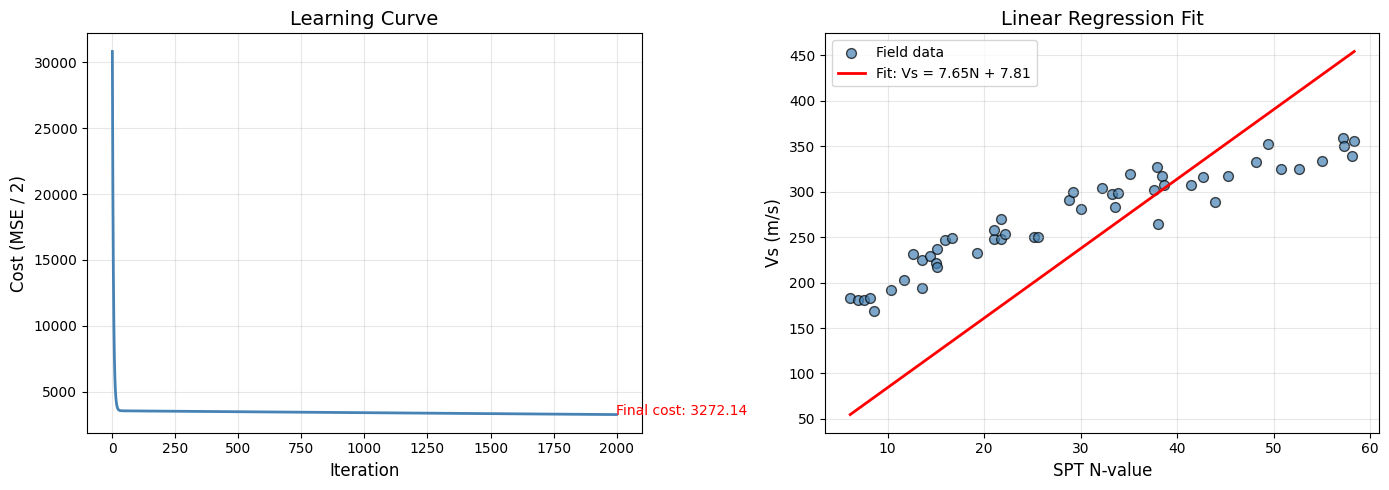

Left:  Cost decreases rapidly then plateaus — the model converged.
Right: The red line captures the general trend in the data.


In [8]:
# ─────────────────────────────────────────────────────
# LEARNING CURVE — Cost over iterations
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Learning curve
axes[0].plot(costs, color="steelblue", linewidth=2)
axes[0].set_xlabel("Iteration", fontsize=12)
axes[0].set_ylabel("Cost (MSE / 2)", fontsize=12)
axes[0].set_title("Learning Curve", fontsize=14)
axes[0].grid(True, alpha=0.3)
axes[0].annotate(f"Final cost: {costs[-1]:.2f}",
                 xy=(len(costs)-1, costs[-1]),
                 fontsize=10, color="red")

# Right: Data + best-fit line
axes[1].scatter(N_values, Vs_true, c="steelblue", edgecolors="k",
                alpha=0.7, s=50, label="Field data")
x_line = np.linspace(N_values.min(), N_values.max(), 100)
y_line = w_final * x_line + b_final
axes[1].plot(x_line, y_line, "r-", linewidth=2,
             label=f"Fit: Vs = {w_final:.2f}N + {b_final:.2f}")
axes[1].set_xlabel("SPT N-value", fontsize=12)
axes[1].set_ylabel("Vs (m/s)", fontsize=12)
axes[1].set_title("Linear Regression Fit", fontsize=14)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Left:  Cost decreases rapidly then plateaus — the model converged.")
print("Right: The red line captures the general trend in the data.")

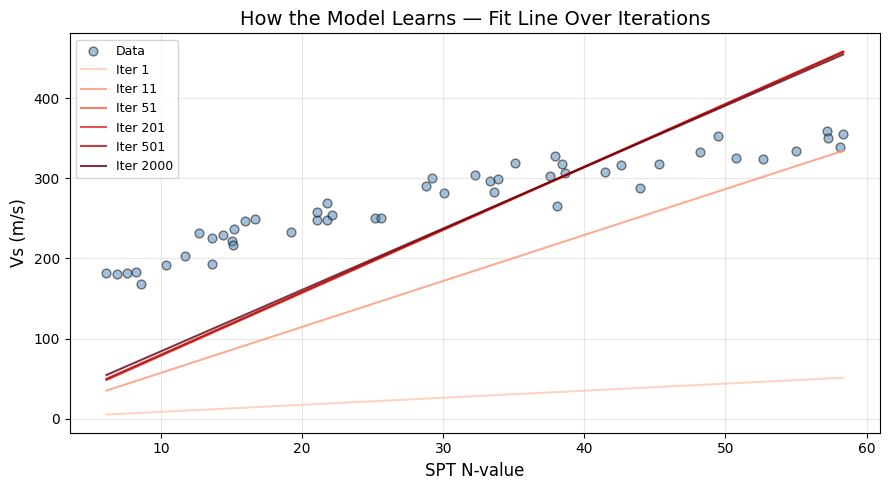

The line starts flat (w=0, b=0) and rotates into position.
Gradient descent adjusts slope and intercept simultaneously.


In [9]:
# ─────────────────────────────────────────────────────
# EVOLUTION OF THE FIT LINE — Watch the model learn
# ─────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(N_values, Vs_true, c="steelblue", edgecolors="k",
           alpha=0.5, s=40, label="Data")

# Show fit line at different stages of training
snapshots = [0, 10, 50, 200, 500, n_iterations - 1]
colors = plt.cm.Reds(np.linspace(0.2, 1.0, len(snapshots)))

for idx, snap in enumerate(snapshots):
    y_snap = w_hist[snap] * x_line + b_hist[snap]
    ax.plot(x_line, y_snap, color=colors[idx], linewidth=1.5,
            alpha=0.8, label=f"Iter {snap+1}")

ax.set_xlabel("SPT N-value", fontsize=12)
ax.set_ylabel("Vs (m/s)", fontsize=12)
ax.set_title("How the Model Learns — Fit Line Over Iterations", fontsize=14)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("The line starts flat (w=0, b=0) and rotates into position.")
print("Gradient descent adjusts slope and intercept simultaneously.")

---

## Part 7: Effect of Learning Rate

The learning rate $\alpha$ controls how big each update step is:
- **Too small** → converges very slowly (needs many iterations)
- **Too large** → overshoots and diverges (cost goes to infinity)
- **Just right** → converges quickly and smoothly

  Iter     0 | Cost:   37360.38 | w:  0.0880 | b:   0.0027
  Iter   200 | Cost:    3931.67 | w:  7.0358 | b:   0.2638
  Iter   400 | Cost:    3559.21 | w:  7.7644 | b:   0.3607
  Iter   600 | Cost:    3552.12 | w:  7.8392 | b:   0.4403
  Iter   800 | Cost:    3549.06 | w:  7.8452 | b:   0.5181
  Iter   999 | Cost:    3546.07 | w:  7.8440 | b:   0.5952

  Iter     0 | Cost:   30820.65 | w:  0.8795 | b:   0.0271
  Iter   200 | Cost:    3530.92 | w:  7.8338 | b:   0.9862
  Iter   400 | Cost:    3501.13 | w:  7.8134 | b:   1.7579
  Iter   600 | Cost:    3471.59 | w:  7.7931 | b:   2.5262
  Iter   800 | Cost:    3442.32 | w:  7.7730 | b:   3.2911
  Iter   999 | Cost:    3413.45 | w:  7.7530 | b:   4.0489

  Iter     0 | Cost:   10253.73 | w:  4.3977 | b:   0.1355
  Iter   200 | Cost:    3412.72 | w:  7.7525 | b:   4.0680
  Iter   400 | Cost:    3271.44 | w:  7.6533 | b:   7.8254
  Iter   600 | Cost:    3136.27 | w:  7.5563 | b:  11.5007
  Iter   800 | Cost:    3006.94 | w:  7.4615 | b:  15.

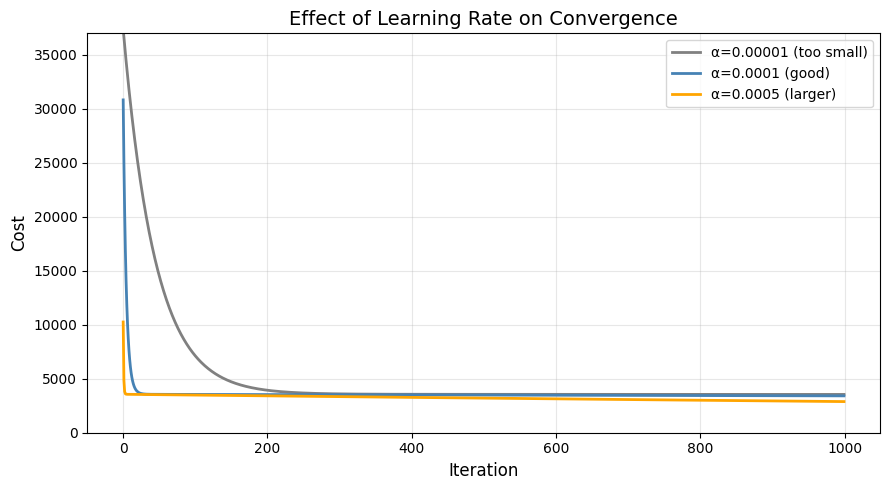

Too small: barely makes progress in 1000 iterations.
Just right: converges quickly and smoothly.
Larger: converges faster but may become unstable if too big.


In [10]:
# ─────────────────────────────────────────────────────
# EFFECT OF LEARNING RATE
# ─────────────────────────────────────────────────────

learning_rates = [0.00001, 0.0001, 0.0005]
labels = ["α=0.00001 (too small)", "α=0.0001 (good)", "α=0.0005 (larger)"]
colors = ["gray", "steelblue", "orange"]

fig, ax = plt.subplots(figsize=(9, 5))

for lr, label, color in zip(learning_rates, labels, colors):
    _, _, cost_hist, _, _ = gradient_descent(
        N_values, Vs_true, 0.0, 0.0, lr, 1000
    )
    ax.plot(cost_hist, label=label, color=color, linewidth=2)
    print()  # Separator between training outputs

ax.set_xlabel("Iteration", fontsize=12)
ax.set_ylabel("Cost", fontsize=12)
ax.set_title("Effect of Learning Rate on Convergence", fontsize=14)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(0, costs[0] * 1.2)
plt.tight_layout()
plt.show()

print("Too small: barely makes progress in 1000 iterations.")
print("Just right: converges quickly and smoothly.")
print("Larger: converges faster but may become unstable if too big.")

---

## Part 8: The Normal Equation — Closed-Form Solution

Instead of iterating, we can solve for the optimal parameters **directly** using linear algebra:

$$\mathbf{w} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$

where $\mathbf{X}$ is the design matrix with a column of ones (for the bias term).

This gives the **exact** optimal solution in one step — no learning rate, no iterations.

In [11]:
# ─────────────────────────────────────────────────────
# NORMAL EQUATION — Closed-form solution
# ─────────────────────────────────────────────────────

# Build design matrix X with bias column
X_design = np.column_stack([N_values, np.ones(n_samples)])
print(f"Design matrix X shape: {X_design.shape}")
print(f"First 5 rows of X:")
print(X_design[:5])
print()

# Normal equation: w = (X^T X)^{-1} X^T y
XtX = X_design.T @ X_design           # X^T * X
XtX_inv = np.linalg.inv(XtX)          # (X^T * X)^{-1}
Xty = X_design.T @ Vs_true            # X^T * y
w_normal = XtX_inv @ Xty              # final parameters

w_ne, b_ne = w_normal[0], w_normal[1]

print(f"Normal equation solution:")
print(f"  w (slope):     {w_ne:.4f}")
print(f"  b (intercept): {b_ne:.4f}")
print()
print(f"Gradient descent solution:")
print(f"  w (slope):     {w_final:.4f}")
print(f"  b (intercept): {b_final:.4f}")
print()

cost_ne = compute_cost(N_values, Vs_true, w_ne, b_ne)
print(f"Cost (normal equation):    {cost_ne:.4f}")
print(f"Cost (gradient descent):   {costs[-1]:.4f}")
print()
print("Both methods should give similar results.")
print("Normal equation is exact; gradient descent approaches it iteratively.")

Design matrix X shape: (50, 2)
First 5 rows of X:
[[6.13214719 1.        ]
 [6.89136866 1.        ]
 [7.5547727  1.        ]
 [8.19459867 1.        ]
 [8.57783761 1.        ]]

Normal equation solution:
  w (slope):     3.2146
  b (intercept): 176.0394

Gradient descent solution:
  w (slope):     7.6538
  b (intercept): 7.8065

Cost (normal equation):    143.9702
Cost (gradient descent):   3272.1445

Both methods should give similar results.
Normal equation is exact; gradient descent approaches it iteratively.


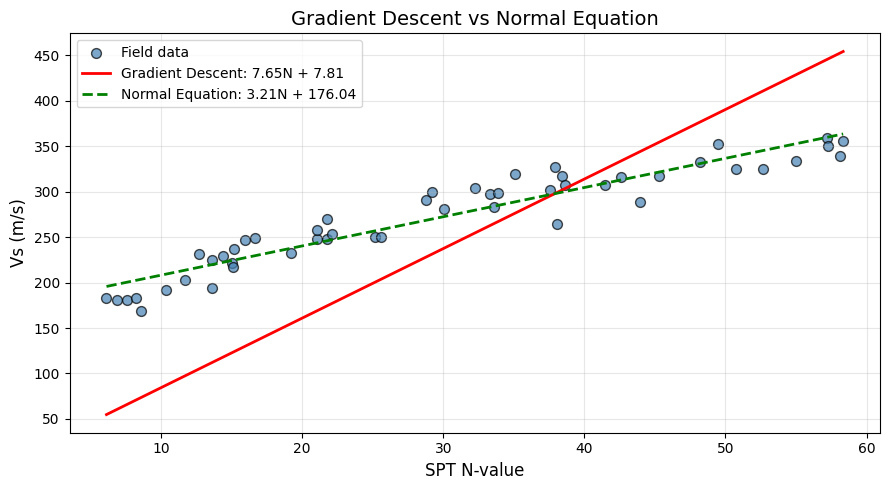

Both lines should overlap closely.
Normal equation gives the exact answer; GD approaches it.


In [12]:
# ─────────────────────────────────────────────────────
# COMPARE BOTH SOLUTIONS VISUALLY
# ─────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(N_values, Vs_true, c="steelblue", edgecolors="k",
           alpha=0.7, s=50, label="Field data")

# Gradient descent line
y_gd = w_final * x_line + b_final
ax.plot(x_line, y_gd, "r-", linewidth=2,
        label=f"Gradient Descent: {w_final:.2f}N + {b_final:.2f}")

# Normal equation line
y_ne = w_ne * x_line + b_ne
ax.plot(x_line, y_ne, "g--", linewidth=2,
        label=f"Normal Equation: {w_ne:.2f}N + {b_ne:.2f}")

ax.set_xlabel("SPT N-value", fontsize=12)
ax.set_ylabel("Vs (m/s)", fontsize=12)
ax.set_title("Gradient Descent vs Normal Equation", fontsize=14)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Both lines should overlap closely.")
print("Normal equation gives the exact answer; GD approaches it.")

---

## Part 9: Model Evaluation — R-squared

In [13]:
# ─────────────────────────────────────────────────────
# R-SQUARED — How well does the model explain variance?
# ─────────────────────────────────────────────────────

def r_squared(y_true, y_pred):
    """Compute R-squared (coefficient of determination)."""
    ss_res = np.sum((y_true - y_pred) ** 2)    # residual sum of squares
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)  # total sum of squares
    return 1 - (ss_res / ss_tot)

# Predictions from gradient descent model
Vs_pred_gd = w_final * N_values + b_final
r2_gd = r_squared(Vs_true, Vs_pred_gd)

# Predictions from normal equation
Vs_pred_ne = w_ne * N_values + b_ne
r2_ne = r_squared(Vs_true, Vs_pred_ne)

# Root Mean Squared Error
rmse_gd = np.sqrt(np.mean((Vs_true - Vs_pred_gd) ** 2))
rmse_ne = np.sqrt(np.mean((Vs_true - Vs_pred_ne) ** 2))

print("Model Evaluation")
print("═" * 45)
print(f"{'Metric':<20} {'Grad. Descent':>12} {'Normal Eq.':>12}")
print("─" * 45)
print(f"{'R²':<20} {r2_gd:>12.4f} {r2_ne:>12.4f}")
print(f"{'RMSE (m/s)':<20} {rmse_gd:>12.2f} {rmse_ne:>12.2f}")
print("═" * 45)
print()
print("R² interpretation:")
print("  0.0 = model explains nothing (predicts the mean)")
print("  1.0 = perfect fit (no residual error)")
print(f"  Our model explains {r2_ne*100:.1f}% of the variance in Vs.")

Model Evaluation
═════════════════════════════════════════════
Metric               Grad. Descent   Normal Eq.
─────────────────────────────────────────────
R²                        -1.3007       0.8988
RMSE (m/s)                  80.90        16.97
═════════════════════════════════════════════

R² interpretation:
  0.0 = model explains nothing (predicts the mean)
  1.0 = perfect fit (no residual error)
  Our model explains 89.9% of the variance in Vs.


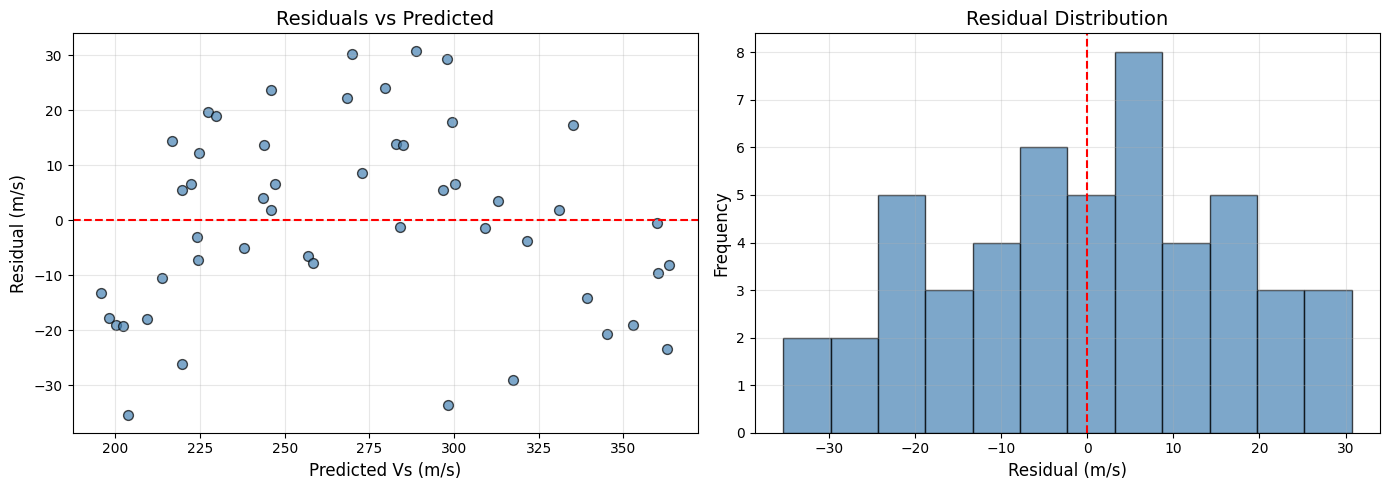

Mean residual:  -0.00 m/s (should be near 0)
Std residual:   16.97 m/s

Look for patterns in the residual plot:
  Random scatter → linear model is appropriate
  Curved pattern → relationship may be nonlinear


In [14]:
# ─────────────────────────────────────────────────────
# RESIDUAL PLOT
# ─────────────────────────────────────────────────────

residuals = Vs_true - Vs_pred_ne

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs predicted
axes[0].scatter(Vs_pred_ne, residuals, c="steelblue", edgecolors="k",
                alpha=0.7, s=50)
axes[0].axhline(y=0, color="red", linestyle="--", linewidth=1.5)
axes[0].set_xlabel("Predicted Vs (m/s)", fontsize=12)
axes[0].set_ylabel("Residual (m/s)", fontsize=12)
axes[0].set_title("Residuals vs Predicted", fontsize=14)
axes[0].grid(True, alpha=0.3)

# Residual histogram
axes[1].hist(residuals, bins=12, color="steelblue", edgecolor="k", alpha=0.7)
axes[1].axvline(x=0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_xlabel("Residual (m/s)", fontsize=12)
axes[1].set_ylabel("Frequency", fontsize=12)
axes[1].set_title("Residual Distribution", fontsize=14)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean residual:  {np.mean(residuals):.2f} m/s (should be near 0)")
print(f"Std residual:   {np.std(residuals):.2f} m/s")
print()
print("Look for patterns in the residual plot:")
print("  Random scatter → linear model is appropriate")
print("  Curved pattern → relationship may be nonlinear")

---

## Part 10: Making Predictions

In [15]:
# ─────────────────────────────────────────────────────
# PREDICT Vs FOR NEW SPT N-VALUES
# ─────────────────────────────────────────────────────

new_N = np.array([10, 20, 30, 40, 50])
new_Vs_pred = w_ne * new_N + b_ne
new_Vs_empirical = 97 * new_N**0.314

print("Predictions for new SPT N-values")
print("═" * 50)
print(f"{'N-value':>8} {'Linear Model':>14} {'Empirical':>12} {'Diff':>8}")
print("─" * 50)
for n, vp, ve in zip(new_N, new_Vs_pred, new_Vs_empirical):
    diff = vp - ve
    print(f"{n:8d} {vp:13.1f} {ve:11.1f} {diff:+7.1f}")
print("═" * 50)
print()
print("Note: The linear model approximates a nonlinear relationship.")
print("It works well in the middle range but deviates at extremes.")
print("Tomorrow we'll use sklearn; Day 038 covers polynomial regression.")

Predictions for new SPT N-values
══════════════════════════════════════════════════
 N-value   Linear Model    Empirical     Diff
──────────────────────────────────────────────────
      10         208.2       199.9    +8.3
      20         240.3       248.5    -8.1
      30         272.5       282.2    -9.7
      40         304.6       308.9    -4.3
      50         336.8       331.3    +5.5
══════════════════════════════════════════════════

Note: The linear model approximates a nonlinear relationship.
It works well in the middle range but deviates at extremes.
Tomorrow we'll use sklearn; Day 038 covers polynomial regression.


---

## Practice Exercises

### Exercise 1: Feature Scaling
Normalize N_values to [0, 1] using min-max scaling: `x_norm = (x - x_min) / (x_max - x_min)`. Re-run gradient descent with a higher learning rate (e.g., 0.1). Does it converge faster?

### Exercise 2: Different Correlation
Generate data using the correlation `qu = 12.5 * N` (unconfined compressive strength vs N-value). Implement linear regression from scratch and compare your learned slope to 12.5.

### Exercise 3: Batch vs Single Sample Gradient
Modify `compute_gradients` to use only ONE random data point per iteration (stochastic gradient descent). Compare the learning curve to full-batch gradient descent.

In [16]:
# EXERCISE 1: Feature Scaling
# N_norm = (N_values - N_values.min()) / (N_values.max() - N_values.min())
# w_scaled, b_scaled, costs_scaled, _, _ = gradient_descent(
#     N_norm, Vs_true, 0.0, 0.0, alpha=0.1, n_iters=200
# )
# plt.plot(costs_scaled)
# plt.show()

In [17]:
# EXERCISE 2: UCS Correlation
# N_ex = np.random.uniform(5, 50, 40)
# qu = 12.5 * N_ex + np.random.normal(0, 20, 40)
# w_qu, b_qu, _, _, _ = gradient_descent(N_ex, qu, 0.0, 0.0, 0.0001, 2000)
# print(f"Learned slope: {w_qu:.2f} (true: 12.5)")

In [18]:
# EXERCISE 3: Stochastic Gradient Descent
# def sgd(x, y, w, b, alpha, n_iters):
#     costs = []
#     for i in range(n_iters):
#         idx = np.random.randint(len(x))
#         xi, yi = x[idx], y[idx]
#         y_pred = w * xi + b
#         dw = (y_pred - yi) * xi
#         db = (y_pred - yi)
#         w -= alpha * dw
#         b -= alpha * db
#         costs.append(compute_cost(x, y, w, b))
#     return w, b, costs

---

## Key Takeaways

1. **Linear regression** finds the best-fit line $\hat{y} = wx + b$ by minimizing the mean squared error between predictions and true values.

2. **Gradient descent** is an iterative optimization algorithm: compute gradients, update parameters in the opposite direction, repeat. The learning rate controls step size.

3. **The normal equation** gives the exact solution in one step using linear algebra, without needing a learning rate or iterations. It is preferred for small datasets.

4. **R-squared** measures how much variance the model explains. Residual plots reveal whether the linear assumption is appropriate.

5. For the **N-value to Vs** relationship, a linear model captures the general trend but cannot fully model the nonlinear power-law relationship. Polynomial regression (Day 038) will address this.

---

## How This Connects to ML

| Today's Concept | ML Equivalent |
|----------------|---------------|
| Cost function (MSE) | Loss function in neural networks |
| Gradient descent | Backpropagation, Adam, SGD optimizers |
| Learning rate α | Hyperparameter tuning |
| Normal equation | Analytical solutions (only for linear models) |
| w (weight) and b (bias) | Model parameters (millions in deep learning) |
| Convergence curve | Training loss plot — the #1 diagnostic tool |
| Residual analysis | Error analysis in model evaluation |
| Feature (N-value) | Input variable in any ML model |

Tomorrow (Day 037) we use **scikit-learn** to do all of this in 3 lines of code — but today you learned what those 3 lines actually do under the hood.

---

*Day 036 of 100 — You just built your first ML model from scratch!*